Imports

In [154]:
from ydata_profiling import ProfileReport
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Importing data and making data profile

In [155]:
DATA_DIR = Path("..") / "data"
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")

In [156]:
REPORTS_DIR = Path("..") / "reports"
report_path_f = REPORTS_DIR / "freight_profile.html"
report_path_w = REPORTS_DIR / "weather_profile.html"
if not report_path_f.exists():
    profile_freight = ProfileReport(df_freight, title="Rhine Freight - Data Profile", explorative=True)
    profile_freight.to_file(report_path_f)
    profile_weather = ProfileReport(df_weather, title="Weather Data Basel - Data Profile", explorative=True)
    profile_weather.to_file(report_path_w)

exploring

In [157]:
df_freight.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar'],
      dtype='object')

# Missing values

In [158]:
df_freight.shape


(1713, 8)

In [159]:
df_freight.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1713 entries, 0 to 1712
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          1469 non-null   object 
 1   Freight       1454 non-null   float64
 2   Mogas_Flat    1469 non-null   float64
 3   Brent_flat    1469 non-null   float64
 4   Diesel_Flat   1469 non-null   float64
 5   Heating_Flat  1469 non-null   float64
 6   Kaub_level    1456 non-null   float64
 7   freight_ar    723 non-null    float64
dtypes: float64(7), object(1)
memory usage: 107.2+ KB


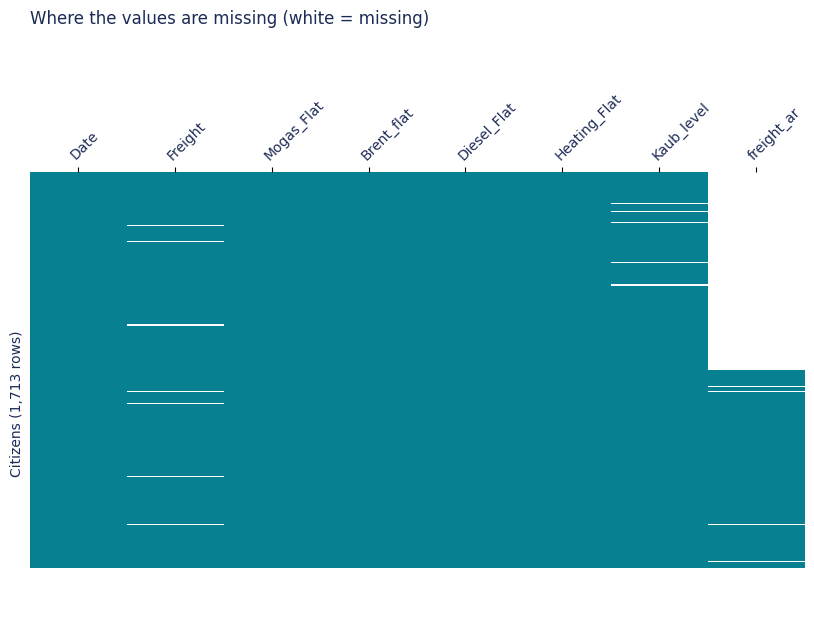

In [160]:
from matplotlib.colors import ListedColormap

NAVY, TEAL = "#1c2a56", "#078091"
FILL = TEAL                    # colour of the cells that have a value
TEXT = NAVY


SORT_ROWS = False              # True: group citizens with the same gaps together (blocks are easier to see)
present = df_freight.notna()
if SORT_ROWS:
    present = present.sort_values(list(present.columns), ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(present.values, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["white", FILL]), vmin=0, vmax=1)   # True = coloured, NaN = white

ax.set_xticks(range(present.shape[1]))
ax.xaxis.tick_top()
ax.set_xticklabels(present.columns, rotation=45, ha="left", rotation_mode="anchor", color=TEXT)
ax.set_ylabel(f"Citizens ({len(df_freight):,} rows)", color=TEXT)
ax.set_yticks([])
ax.set_title("Where the values are missing (white = missing)", loc="left", color=TEXT, pad=48)
for s in ax.spines.values():
    s.set_visible(False)

plt.show()

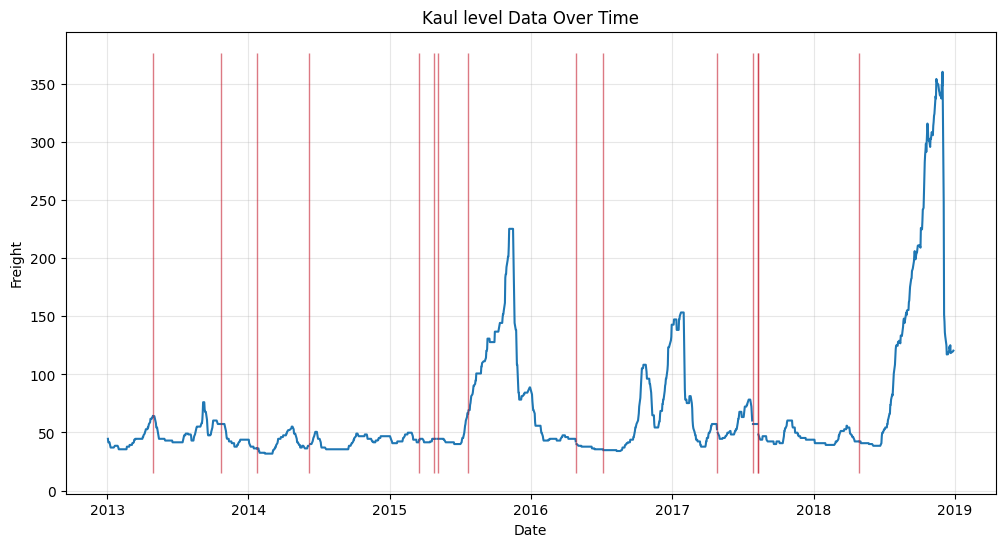

81     2013-04-30
198    2013-10-23
257    2014-01-23
347    2014-06-06
538    2015-03-17
          ...    
1708          NaT
1709          NaT
1710          NaT
1711          NaT
1712          NaT
Name: Date, Length: 259, dtype: datetime64[ns]


In [161]:
#looking at the gaps

df_freight["Date"] = pd.to_datetime(df_freight["Date"], format="%d/%m/%Y")
df_freight = df_freight.sort_values("Date")

missing_dates = df_freight.loc[df_freight["Freight"].isna(), "Date"]


fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_freight["Date"], df_freight['Freight'])
ax.set_title("Kaul level Data Over Time")
ax.vlines(missing_dates, *ax.get_ylim(), color="#c52030", alpha=0.6, lw=1,
          label=f"Missing ({len(missing_dates)} days)")
ax.set_xlabel("Date")
ax.set_ylabel("Freight")
ax.grid(True, alpha=0.3)
plt.show()
plt.close(fig)

print(missing_dates)

In [162]:
df_freight[df_freight['Date'].isin(missing_dates)]

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
81,2013-04-30,NaN,559.305727,232.848837,525.593020,506.796741,334.0,NaN
198,2013-10-23,NaN,500.419638,235.078534,503.151672,491.096794,248.0,NaN
257,2014-01-23,NaN,499.689519,242.217171,508.038980,497.655332,215.0,NaN
347,2014-06-06,NaN,534.086080,239.305087,487.983963,477.286473,170.0,NaN
538,2015-03-17,NaN,502.542519,145.698166,471.538460,440.747821,206.0,NaN
...,...,...,...,...,...,...,...,...
1708,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1709,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1710,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1711,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN


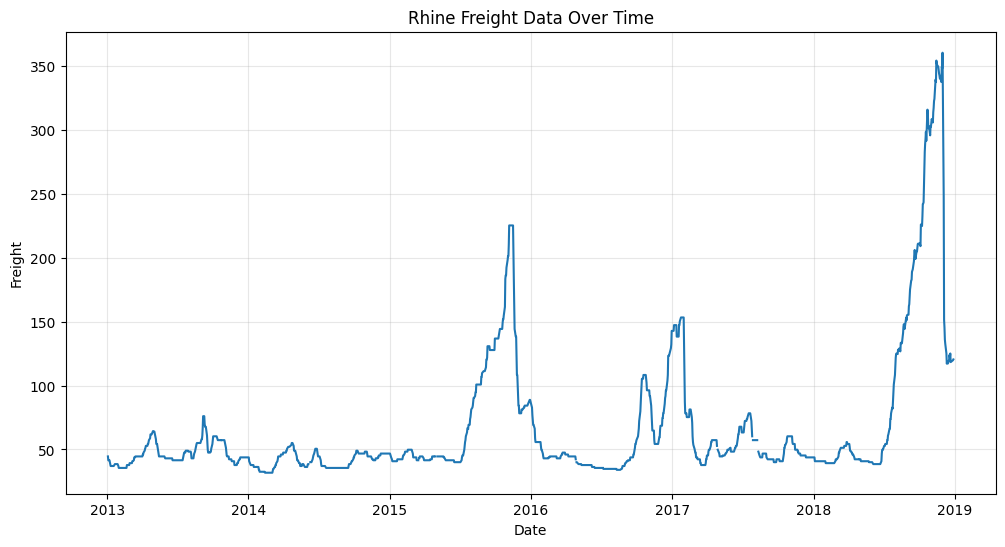

In [163]:
df_freight["Date"] = pd.to_datetime(df_freight["Date"], format="%d/%m/%Y")
df_freight = df_freight.sort_values("Date")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_freight["Date"], df_freight['Freight'])
ax.set_title("Rhine Freight Data Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Freight")
ax.grid(True, alpha=0.3)
plt.show()
plt.close(fig)

- no paired missing values
- unprobable that missings = 0 as seen in the figure
- Missings in the freight_ar before 2016, can be due to new implementation of the tariff at the ar region

Missing values in the target variables (Freight and freight_ar) mean that that training rows are not useful - delete them
Kaub_level missing values can maybe be estimated by surrounding values

In [164]:
df_weather.isna().sum()

date                    365
avg_uv_index            365
avgtemp                 365
cloudcover              365
dewpoint                365
feelslike               365
heatindex               365
humidity                365
maxtemp                 365
mintemp                 365
moon_illumination       365
moon_phase              365
precip                  365
pressure                365
sunhour                 365
totalsnow               365
uv_index                365
visibility              365
weather_code            365
weather_descriptions    365
wind_degree             365
wind_dir                365
wind_speed              365
windchill               365
windgust                365
dtype: int64

no missing values in the weather dataset

In [165]:
print(df_freight.duplicated().sum())
print(df_weather.duplicated().sum())

243
364


there are no duplicates

# Features

In [166]:
df_freight.head(10)

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN
5,2013-01-10,37.05,578.533647,259.139785,581.836410,567.313543,304.0,NaN
6,2013-01-11,37.05,553.267720,249.329516,556.023289,541.716802,297.0,NaN
7,2013-01-14,37.05,548.541638,250.168653,558.254983,544.014828,285.0,NaN
8,2013-01-15,37.05,548.216944,251.444436,561.987579,547.692059,267.0,NaN
9,2013-01-16,37.05,550.397971,250.335166,563.262318,546.577574,251.0,NaN


In [167]:
df_weather.head()

,date,avg_uv_index,avgtemp,cloudcover,dewpoint,feelslike,heatindex,humidity,maxtemp,mintemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,01/01/2009,1.0,-1.0,17.0,-4.0,-6.0,-3.0,95.0,2.0,-5.0,...,0.0,1.0,7.0,113.0,['Clear'],48.0,NE,10.0,-6.0,19.0
1,02/01/2009,1.0,-3.0,63.0,-5.0,-9.0,-3.0,88.0,-2.0,-4.0,...,0.0,1.0,10.0,119.0,['Cloudy'],54.0,NE,17.0,-9.0,26.0
2,03/01/2009,1.0,-7.0,7.0,-12.0,-12.0,-9.0,78.0,-4.0,-11.0,...,0.0,1.0,10.0,113.0,['Clear'],67.0,ENE,6.0,-12.0,13.0
3,04/01/2009,1.0,-8.0,19.0,-12.0,-10.0,-8.0,74.0,-4.0,-10.0,...,0.0,1.0,10.0,116.0,['Partly cloudy'],264.0,W,4.0,-10.0,9.0
4,05/01/2009,1.0,-7.0,74.0,-8.0,-11.0,-6.0,89.0,-5.0,-8.0,...,0.0,1.0,10.0,122.0,['Overcast'],56.0,NE,10.0,-11.0,17.0


In [168]:
#df_freight["freight_ar"] = df_freight["freight_ar"].fillna(0)
#df_freight['Total_Freight'] = df_freight['Freight'] + df_freight['freight_ar']

In [169]:
#df_freight.dropna(subset=['Total_Freight'], inplace=True)
df_freight.shape

(1713, 8)

In [170]:
#df_freight.drop(columns=['Freight', 'freight_ar'], inplace=True)

In [171]:
df_freight.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN


In [172]:
df_weather.drop(columns=['avg_uv_index', 'uv_index'], inplace=True)

In [173]:
df_weather.head()

,date,avgtemp,cloudcover,dewpoint,feelslike,heatindex,humidity,maxtemp,mintemp,moon_illumination,...,sunhour,totalsnow,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,01/01/2009,-1.0,17.0,-4.0,-6.0,-3.0,95.0,2.0,-5.0,31.0,...,8.3,0.0,7.0,113.0,['Clear'],48.0,NE,10.0,-6.0,19.0
1,02/01/2009,-3.0,63.0,-5.0,-9.0,-3.0,88.0,-2.0,-4.0,38.0,...,3.1,0.0,10.0,119.0,['Cloudy'],54.0,NE,17.0,-9.0,26.0
2,03/01/2009,-7.0,7.0,-12.0,-12.0,-9.0,78.0,-4.0,-11.0,45.0,...,8.3,0.0,10.0,113.0,['Clear'],67.0,ENE,6.0,-12.0,13.0
3,04/01/2009,-8.0,19.0,-12.0,-10.0,-8.0,74.0,-4.0,-10.0,52.0,...,8.4,0.0,10.0,116.0,['Partly cloudy'],264.0,W,4.0,-10.0,9.0
4,05/01/2009,-7.0,74.0,-8.0,-11.0,-6.0,89.0,-5.0,-8.0,60.0,...,3.1,0.0,10.0,122.0,['Overcast'],56.0,NE,10.0,-11.0,17.0


Weather correlations

In [174]:
df_freight.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar'],
      dtype='object')

In [175]:

correlation_data = df_freight.copy()
correlation_data["Date"] = pd.to_datetime(correlation_data["Date"]).map(
    lambda date: date.toordinal()
)
correlation_matrix = correlation_data.corr(method="pearson")

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    correlation_matrix,
    mask=mask,       # Hides the upper triangle
    annot=True,
    fmt=".2f",
    cmap="Reds",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Correlation map for all freight features")
fig.tight_layout()
plt.show()


ValueError: NaTType does not support toordinal

- Fuel prices are highly correlated
- Freight prices not correlated with water level and date
- freight_ar correlated with date, fuel and water level. and highly correlated with freight

In [ ]:
df_weather.rename(columns={'date': 'Date'}, inplace=True)
df_weather["Date"] = pd.to_datetime(df_weather["Date"], format="%d/%m/%Y")

Encoding 

In [ ]:
df_weather[['moon_phase', 'weather_descriptions', 'wind_dir']].nunique()

moon_phase               8
weather_descriptions    17
wind_dir                16
dtype: int64

interval columns not set, guessing: ['Date', 'avgtemp', 'cloudcover', 'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp', 'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow', 'visibility', 'weather_code', 'wind_degree', 'wind_speed', 'windchill', 'windgust']


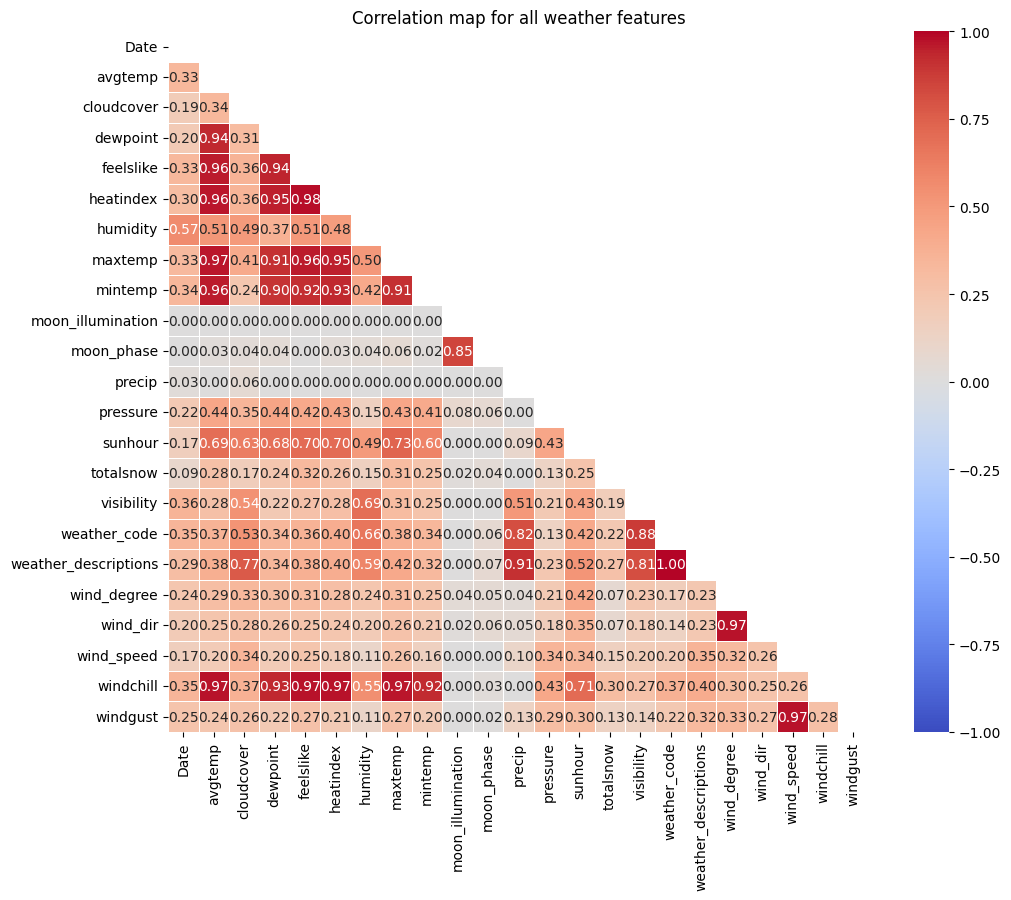

In [ ]:
import phik

correlation_wdata = df_weather.copy()
correlation_wdata["Date"] = pd.to_datetime(correlation_wdata["Date"]).map(
    lambda date: date.toordinal()
)
correlation_matrix = correlation_wdata.phik_matrix()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    correlation_matrix,
    mask=mask,       # Hides the upper triangle
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Correlation map for all weather features")
fig.tight_layout()
plt.show()

- expected correlations between similar features

Joining datasets


In [ ]:
df_complete = pd.merge(df_freight, df_weather, on="Date", how='left')
df_complete.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avgtemp,cloudcover,...,sunhour,totalsnow,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,2,100,...,6.8,0.0,10,122,['Overcast'],245,WSW,7,1,14
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,4,100,...,3.1,0.0,0,248,['Fog'],283,WNW,6,3,12
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,1,24,...,8.4,0.0,10,113,['Clear'],105,ESE,5,-2,10
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,0,3,...,8.4,0.0,10,113,['Clear'],210,SSW,4,0,8
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,-1,54,...,5.0,0.0,5,143,['Mist'],273,W,5,-3,10
